# Scientific Computing Lab – Interpolation of a NACA 4-Digit Cambered Airfoil

 Lagrange interpolation and a manually implemented cubic spline.


## 1. Import libraries and select NACA parameters

For a NACA four-digit airfoil, the parameters are:
- `m`: maximum camber as a fraction of chord
- `p`: location of maximum camber as a fraction of chord
- `t`: maximum thickness as a fraction of chord

A fixed random seed is used so that the same airfoil is generated every time the notebook is run. Change or remove the seed if a different random airfoil is required.

In [33]:
import numpy as np
import matplotlib.pyplot as plt


m_digit = np.random.randint(1, 6)       
p_digit = np.random.randint(2, 8)   
t_digit = np.random.randint(8, 20)     

m = m_digit / 100
p = p_digit / 10
t = t_digit / 100

naca_code = f"{m_digit}{p_digit}{t_digit:02d}"
print("Selected NACA airfoil: NACA", naca_code)
print(f"Maximum camber (m) = {m:.2f}")
print(f"Location of maximum camber (p) = {p:.2f}")
print(f"Maximum thickness (t) = {t:.2f}")

Selected NACA airfoil: NACA 5414
Maximum camber (m) = 0.05
Location of maximum camber (p) = 0.40
Maximum thickness (t) = 0.14


## 2. Generate the original NACA airfoil

Cosine spacing is used to generate the original airfoil coordinates. It places more points near the leading and trailing edges, where the geometry changes more rapidly.

The thickness distribution and camber-line equations are evaluated, and the upper and lower surfaces are obtained using the local camber-line angle.

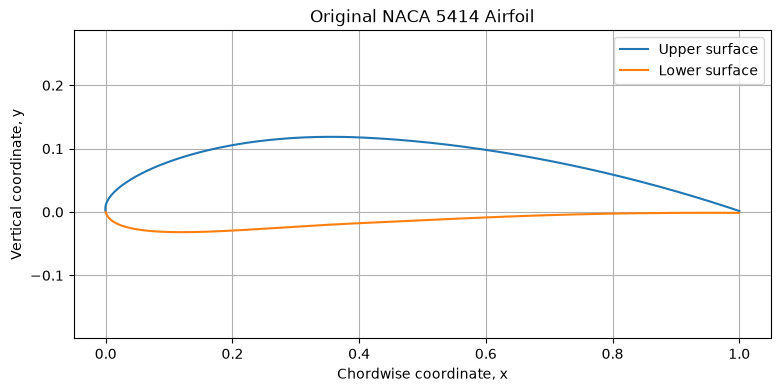

In [34]:
def generate_naca_airfoil(x, m, p, t):
    yt = 5 * t * (
        0.2969 * np.sqrt(x)
        - 0.1260 * x
        - 0.3516 * x**2
        + 0.2843 * x**3
        - 0.1015 * x**4
    )

    yc = np.zeros_like(x, dtype=float)
    dyc_dx = np.zeros_like(x, dtype=float)

    for i, xi in enumerate(x):
        if xi <= p:
            yc[i] = (m / p**2) * (2 * p * xi - xi**2)
            dyc_dx[i] = (2 * m / p**2) * (p - xi)
        else:
            yc[i] = (m / (1 - p)**2) * (
                1 - 2 * p + 2 * p * xi - xi**2
            )
            dyc_dx[i] = (2 * m / (1 - p)**2) * (p - xi)

    theta = np.arctan(dyc_dx)

    xu = x - yt * np.sin(theta)
    yu = yc + yt * np.cos(theta)
    xl = x + yt * np.sin(theta)
    yl = yc - yt * np.cos(theta)

    return xu, yu, xl, yl

number_original = 501
beta = np.linspace(0, np.pi, number_original)
x_original = (1 - np.cos(beta)) / 2

xu_original, yu_original, xl_original, yl_original = (
    generate_naca_airfoil(x_original, m, p, t)
)

plt.figure(figsize=(9, 4))
plt.plot(xu_original, yu_original, label="Upper surface")
plt.plot(xl_original, yl_original, label="Lower surface")
plt.xlabel("Chordwise coordinate, x")
plt.ylabel("Vertical coordinate, y")
plt.title(f"Original NACA {naca_code} Airfoil")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## 3. Lagrange interpolation function

The Lagrange polynomial is

$$
P(x)=\sum_{i=0}^{n-1} y_i L_i(x)
$$

where

$$
L_i(x)=\prod_{\substack{j=0\\j\ne i}}^{n-1}
\frac{x-x_j}{x_i-x_j}.
$$

The function below evaluates the polynomial at all requested points. It is implemented directly using loops and does not use SciPy.

In [35]:
def lagrange_interpolation(x_data, y_data, x_query):
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    x_query = np.asarray(x_query, dtype=float)

    result = np.zeros_like(x_query, dtype=float)

    for i in range(len(x_data)):
        basis = np.ones_like(x_query, dtype=float)

        for j in range(len(x_data)):
            if i != j:
                basis *= (x_query - x_data[j]) / (x_data[i] - x_data[j])

        result += y_data[i] * basis

    return result

## 4. Cubic spline – algorithm

A cubic spline fits a separate cubic polynomial between every pair of adjacent data points:

$$
S_i(x)=a_i+b_i(x-x_i)+c_i(x-x_i)^2+d_i(x-x_i)^3.
$$

For a **cubic spline**, the second derivatives at the two end points are zero:

$$
M_0=0, \qquad M_{n-1}=0.
$$

Let \(h_i=x_{i+1}-x_i\). The unknown second derivatives at the interior points satisfy

$$
h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}
=6\left[\frac{y_{i+1}-y_i}{h_i}
-\frac{y_i-y_{i-1}}{h_{i-1}}\right].
$$

This produces a tridiagonal system of equations.

**Algorithm**
1. Calculate the interval widths, \(h_i=x_{i+1}-x_i\).
2. Form the tridiagonal equations for the interior second derivatives.
3. Solve the equations using the Thomas algorithm (forward elimination followed by back substitution).
4. Set the two end second derivatives to zero.
5. For each query point, identify its interval and evaluate the corresponding cubic polynomial.

The Thomas algorithm is used instead of a general-purpose interpolation routine. It is efficient because the coefficient matrix is tridiagonal.

## 5. Implement the cubic spline from scratch

The function below first calculates the second derivatives at the data points. It then evaluates the appropriate cubic polynomial for each query coordinate.

The input coordinates must be strictly increasing and contain at least two points.

In [36]:

def cubic_spline(x, y, x_new):
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    x_new = np.array(x_new, dtype=float)

    n = len(x)
    if n < 2:
        raise ValueError("At least two points are needed.")
    if len(x) != len(y):
        raise ValueError("Both arrays must have the same length.")
    if np.any(np.diff(x) <= 0):
        raise ValueError("X values must be in increasing order.")

    h = np.diff(x)
    M = np.zeros(n)
    count = n - 2

    if count > 0:
        a = h[:-1].copy()
        b = 2 * (h[:-1] + h[1:])
        c = h[1:].copy()
        slope = np.diff(y) / h
        d = 6 * np.diff(slope)

        for i in range(1, count):
            factor = a[i - 1] / b[i - 1]
            b[i] = b[i] - factor * c[i - 1]
            d[i] = d[i] - factor * d[i - 1]

        M_inside = np.zeros(count)
        M_inside[-1] = d[-1] / b[-1]

        for i in range(count - 2, -1, -1):
            M_inside[i] = (d[i] - c[i] * M_inside[i + 1]) / b[i]

        M[1:-1] = M_inside


    index = np.searchsorted(x, x_new) - 1
    index = np.clip(index, 0, n - 2)

    x1 = x[index]
    x2 = x[index + 1]

    width = x2 - x1

    left = x2 - x_new
    right = x_new - x1

    M1 = M[index]
    M2 = M[index + 1]

    result = (M1 * left**3 / (6 * width)+ M2 * right**3 / (6 * width)+ (y[index] - M1 * width**2 / 6) * left / width+ (y[index + 1] - M2 * width**2 / 6) * right / width)

    return result


## 6. Error calculation

The maximum absolute error and root mean square (RMS) error are used to measure the difference between the original airfoil and the reconstructed surface.

$$
E_{max}=\max_i |y_i-\hat y_i|
$$

$$
E_{RMS}=\sqrt{\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat y_i)^2}
$$

The upper and lower surface errors are combined so that both surfaces contribute to the final error values.

In [37]:
def calculate_errors(actual_upper, estimated_upper,actual_lower, estimated_lower):
    upper_error = actual_upper - estimated_upper
    lower_error = actual_lower - estimated_lower

    combined_error = np.concatenate((upper_error, lower_error))

    maximum_error = np.max(np.abs(combined_error))
    rms_error = np.sqrt(np.mean(combined_error**2))

    return maximum_error, rms_error

## 7. Reconstruct the airfoil using different point spacings

The same number of sample points is used for both spacing methods:
- **Uniform spacing:** points are equally spaced along the chord.
- **Cosine spacing:** points are clustered near the leading and trailing edges.

The interpolation is carried out independently for the upper and lower surfaces. The manually implemented spline is used in place of SciPy's `CubicSpline`.

In [38]:
sample_count = 11

x_query = np.linspace(0, 1, 500)
_, upper_exact, _, lower_exact = generate_naca_airfoil(x_query, m, p, t)

spacing_results = {}
reconstructed_curves = {}

for spacing_name in ("Uniform", "Cosine"):
    if spacing_name == "Uniform":
        x_sample = np.linspace(0, 1, sample_count)
    else:
        beta_sample = np.linspace(0, np.pi, sample_count)
        x_sample = (1 - np.cos(beta_sample)) / 2

    _, upper_sample, _, lower_sample = generate_naca_airfoil(
        x_sample, m, p, t
    )

    upper_lagrange = lagrange_interpolation(x_sample, upper_sample, x_query)
    lower_lagrange = lagrange_interpolation(x_sample, lower_sample, x_query)

    upper_spline = cubic_spline(x_sample, upper_sample, x_query)
    lower_spline = cubic_spline(x_sample, lower_sample, x_query)

    lag_max, lag_rms = calculate_errors(upper_exact, upper_lagrange,lower_exact, lower_lagrange)
    spline_max, spline_rms = calculate_errors(upper_exact, upper_spline,lower_exact, lower_spline)

    spacing_results[spacing_name] = {
        "Lagrange max": lag_max,
        "Lagrange RMS": lag_rms,
        "Spline max": spline_max,
        "Spline RMS": spline_rms
    }

    reconstructed_curves[spacing_name] = {
        "x_sample": x_sample,
        "upper_sample": upper_sample,
        "lower_sample": lower_sample,
        "upper_lagrange": upper_lagrange,
        "lower_lagrange": lower_lagrange,
        "upper_spline": upper_spline,
        "lower_spline": lower_spline
    }

print("Reconstruction error comparison")
print("-" * 76)
print(f"{'Spacing':<12}{'Method':<14}{'Maximum error':>18}{'RMS error':>16}")

for spacing_name, values in spacing_results.items():
    print(f"{spacing_name:<12}{'Lagrange':<14}"
          f"{values['Lagrange max']:>18.8e}{values['Lagrange RMS']:>16.8e}")
    print(f"{'':<12}{'Natural spline':<14}"
          f"{values['Spline max']:>18.8e}{values['Spline RMS']:>16.8e}")

Reconstruction error comparison
----------------------------------------------------------------------------
Spacing     Method             Maximum error       RMS error
Uniform     Lagrange          9.15683035e-03  1.54180374e-03
            Natural spline    1.42939507e-02  3.04255592e-03
Cosine      Lagrange          6.00822478e-03  1.03282523e-03
            Natural spline    7.29615653e-03  1.44552183e-03


## 8. Plot the reconstructed airfoil

The following plot displays the original airfoil, the Lagrange reconstruction, and the cubic spline reconstruction for cosine-spaced sample points.

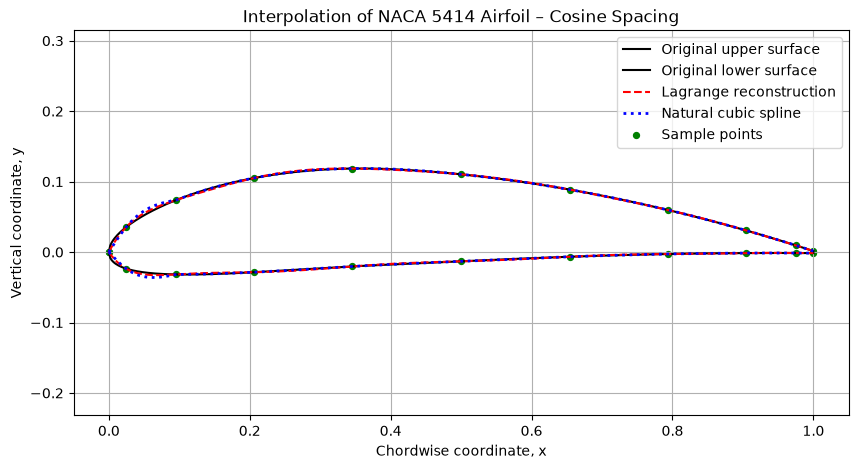

In [39]:
selected = reconstructed_curves["Cosine"]

plt.figure(figsize=(10, 5))
plt.plot(x_query, upper_exact, "k", label="Original upper surface")
plt.plot(x_query, lower_exact, "k", label="Original lower surface")

plt.plot(x_query, selected["upper_lagrange"], "r--",
         label="Lagrange reconstruction")
plt.plot(x_query, selected["lower_lagrange"], "r--")

plt.plot(x_query, selected["upper_spline"], "b:",
         linewidth=2, label="Natural cubic spline")
plt.plot(x_query, selected["lower_spline"], "b:", linewidth=2)

plt.scatter(selected["x_sample"], selected["upper_sample"],
            color="green", s=18, label="Sample points")
plt.scatter(selected["x_sample"], selected["lower_sample"],
            color="green", s=18)

plt.xlabel("Chordwise coordinate, x")
plt.ylabel("Vertical coordinate, y")
plt.title(f"Interpolation of NACA {naca_code} Airfoil – Cosine Spacing")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

## 9. Compare RMS errors for uniform and cosine spacing

This bar chart compares the RMS errors obtained using Lagrange interpolation and the manually implemented cubic spline.

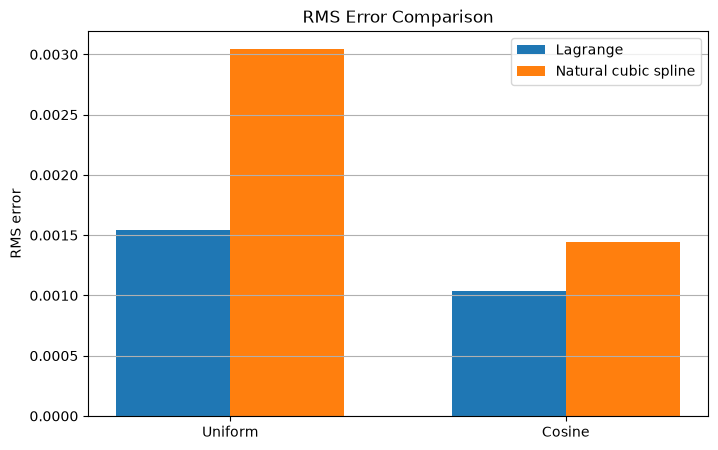

In [40]:
spacing_names = list(spacing_results.keys())
lagrange_rms = [spacing_results[s]["Lagrange RMS"] for s in spacing_names]
spline_rms = [spacing_results[s]["Spline RMS"] for s in spacing_names]

positions = np.arange(len(spacing_names))
bar_width = 0.34

plt.figure(figsize=(8, 5))
plt.bar(positions - bar_width/2, lagrange_rms, bar_width,
        label="Lagrange")
plt.bar(positions + bar_width/2, spline_rms, bar_width,
        label="Natural cubic spline")

plt.xticks(positions, spacing_names)
plt.ylabel("RMS error")
plt.title("RMS Error Comparison")
plt.grid(axis="y")
plt.legend()
plt.show()

## 10. Conclusion

A cambered NACA four-digit airfoil was generated using the NACA thickness and camber equations. The upper and lower surfaces were reconstructed using Lagrange interpolation and a cubic spline.

The cubic spline was implemented manually by calculating the second derivatives at the data points and solving the resulting tridiagonal system using the Thomas algorithm. Therefore, the spline calculation does not depend on SciPy.

Uniform and cosine spacing were compared using maximum absolute error and RMS error. The numerical results printed by the notebook should be used when writing the final discussion. In general, cosine spacing places more points near the leading and trailing edges, which can help represent regions with greater curvature. The actual error values depend on the selected airfoil parameters and number of sample points.

## References

1. Numerical Recipes, *The Art of Scientific Computing*, Cambridge University Press.
2. NACA airfoil geometry equations for four-digit airfoils.
3. NumPy documentation – array operations and numerical calculations.
4. Matplotlib documentation – plotting and visualization.